# Phase 1: Enhancement (evangeline, TUMOUR, patient 29)

| Step | This member's algorithms |
|---|---|
| Windowing | **narrow liver window**, level 90 / width 150 (this patient's tumour is only ~17 HU darker than the liver) |
| Spatial filter | **anisotropic diffusion** (edge-preserving) vs **median** |
| Contrast | **CLAHE** vs **histogram equalisation** |
| Frequency | 2D DFT spectrum + **homomorphic filter** |
| Validation | PSNR + CNR (liver vs surroundings, and the main target: **tumour vs liver**) |

In [1]:
import os, glob
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd

NAME = "evangeline"
SLICES = f"../data/slices/{NAME}"
OUT = "outputs_evangeline"
FIGS = "../report/figures/evangeline"
os.makedirs(f"{OUT}/enhanced", exist_ok=True)
os.makedirs(FIGS, exist_ok=True)

files = sorted(glob.glob(f"{SLICES}/*_ct.npy"))
print(len(files), "slices found")

def load(ct_path):
    base = ct_path.replace("_ct.npy", "")
    return np.load(ct_path), cv2.imread(base + "_liver.png", 0) > 0, cv2.imread(base + "_tumour.png", 0) > 0

example = max(files, key=lambda f: load(f)[2].sum())
ct, liver, tumour = load(example)
print("example slice:", os.path.basename(example), "| tumour pixels:", tumour.sum())
print("median HU  liver:", np.median(ct[liver & ~tumour]), " tumour:", np.median(ct[tumour]))

22 slices found


example slice: p29_s69_ct.npy | tumour pixels: 1206
median HU  liver: 99.0  tumour: 81.0


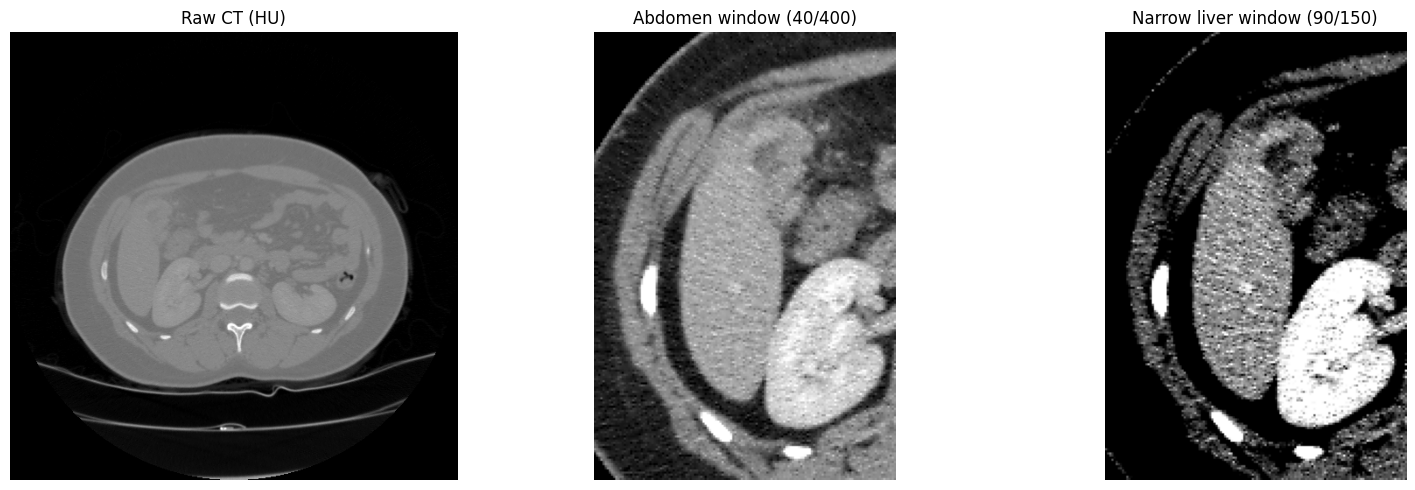

In [2]:
def window(ct, level=90, width=150):
    lo, hi = level - width / 2, level + width / 2          # 90, 150 -> 15 to 165 HU
    return ((np.clip(ct, lo, hi) - lo) / (hi - lo) * 255).astype(np.uint8)

ys, xs = np.where(liver)
r0, r1, c0, c1 = max(ys.min() - 40, 0), ys.max() + 40, max(xs.min() - 40, 0), xs.max() + 40
def crop(img):
    return img[r0:r1, c0:c1]                                # zoom on the liver

def abdomen(ct):
    return ((np.clip(ct, -160, 240) + 160) / 400 * 255).astype(np.uint8)

win = window(ct)
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
ax[0].imshow(ct, cmap="gray"); ax[0].set_title("Raw CT (HU)")
ax[1].imshow(crop(abdomen(ct)), cmap="gray"); ax[1].set_title("Abdomen window (40/400)")
ax[2].imshow(crop(win), cmap="gray"); ax[2].set_title("Narrow liver window (90/150)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p1_windowing.png", dpi=120); plt.show()

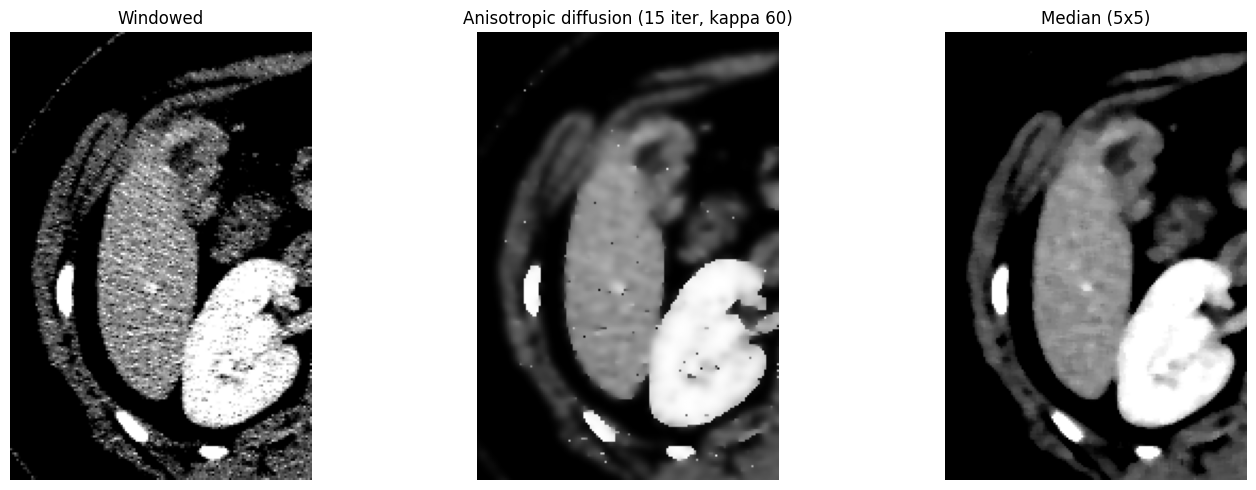

In [3]:
def anisotropic_diffusion(img, iterations=15, kappa=30, gamma=0.15):
    """Perona-Malik diffusion: smooths flat areas, but stops at edges (big brightness jumps)."""
    I = img.astype(np.float64)
    for _ in range(iterations):
        # differences to the 4 neighbours (north, south, east, west)
        diffs = [np.roll(I, -1, 0) - I, np.roll(I, 1, 0) - I, np.roll(I, -1, 1) - I, np.roll(I, 1, 1) - I]
        # conduction: close to 1 for small differences (smooth), close to 0 at edges (keep)
        I = I + gamma * sum(np.exp(-(d / kappa) ** 2) * d for d in diffs)
    return np.clip(I, 0, 255).astype(np.uint8)

KAPPA = 60      # higher than usual: in this narrow window the noise jumps are bigger, so the "edge" level must be higher
aniso = anisotropic_diffusion(win, kappa=KAPPA)
median = cv2.medianBlur(win, 5)
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, im, t in zip(ax, [win, aniso, median], ["Windowed", "Anisotropic diffusion (15 iter, kappa 60)", "Median (5x5)"]):
    a.imshow(crop(im), cmap="gray"); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p1_spatial_filters.png", dpi=120); plt.show()

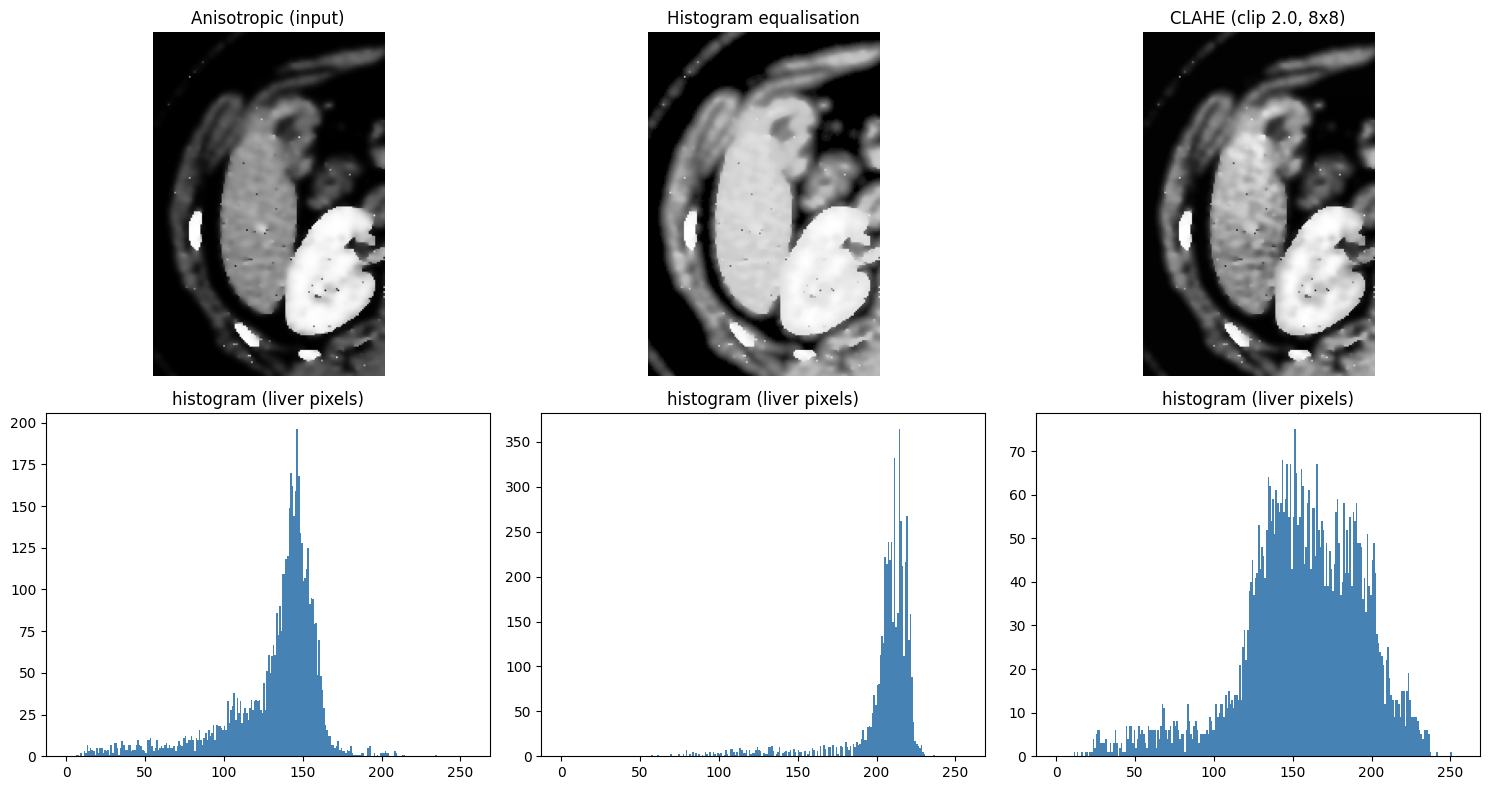

In [4]:
he = cv2.equalizeHist(aniso)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(aniso)
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for j, (im, t) in enumerate([(aniso, "Anisotropic (input)"), (he, "Histogram equalisation"), (clahe, "CLAHE (clip 2.0, 8x8)")]):
    ax[0, j].imshow(crop(im), cmap="gray"); ax[0, j].set_title(t); ax[0, j].axis("off")
    ax[1, j].hist(im[liver].ravel(), bins=256, range=(0, 256), color="steelblue"); ax[1, j].set_title("histogram (liver pixels)")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p1_contrast.png", dpi=120); plt.show()

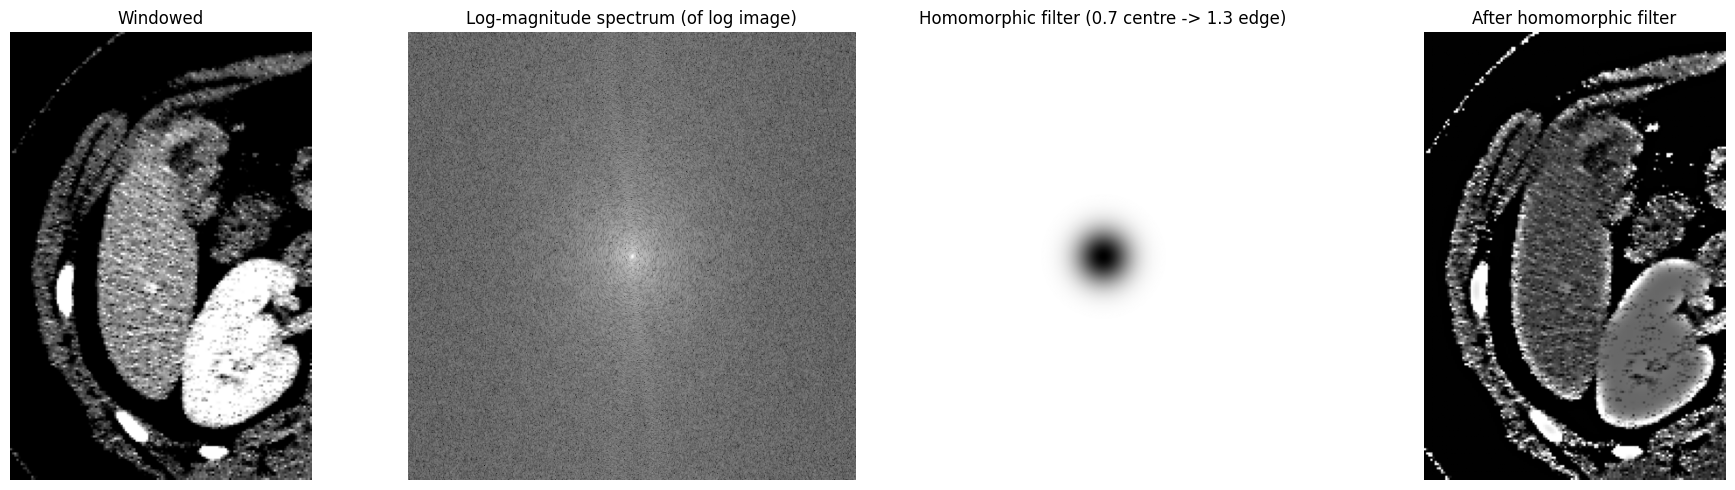

In [5]:
def homomorphic(img, D0=30, gamma_low=0.7, gamma_high=1.3, c=1):
    """Homomorphic filter: image = lighting x reflectance. Taking the log turns x into +,
    then a high-emphasis filter turns DOWN slow lighting changes and turns UP detail."""
    F = np.fft.fftshift(np.fft.fft2(np.log1p(img.astype(np.float64))))
    rows, cols = img.shape
    u, v = np.meshgrid(np.arange(cols) - cols / 2, np.arange(rows) - rows / 2)
    D2 = u ** 2 + v ** 2
    H = (gamma_high - gamma_low) * (1 - np.exp(-c * D2 / D0 ** 2)) + gamma_low
    out = np.expm1(np.real(np.fft.ifft2(np.fft.ifftshift(F * H))))
    lo, hi = np.percentile(out, [1, 99])                  # robust rescale: ignore the few extreme edge pixels
    out = np.clip((out - lo) / (hi - lo + 1e-9), 0, 1) * 255
    return out.astype(np.uint8), F, H

homo, F, H = homomorphic(win)
fig, ax = plt.subplots(1, 4, figsize=(19, 5))
ax[0].imshow(crop(win), cmap="gray"); ax[0].set_title("Windowed")
ax[1].imshow(np.log(1 + np.abs(F)), cmap="gray"); ax[1].set_title("Log-magnitude spectrum (of log image)")
ax[2].imshow(H, cmap="gray"); ax[2].set_title("Homomorphic filter (0.7 centre -> 1.3 edge)")
ax[3].imshow(crop(homo), cmap="gray"); ax[3].set_title("After homomorphic filter")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p1_frequency.png", dpi=120); plt.show()

In [6]:
def psnr(ref, test):
    """How close the processed image stays to the original (dB). Higher = less changed."""
    mse = np.mean((ref.astype(np.float64) - test.astype(np.float64)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255 ** 2 / mse)

def cnr(img, region, background):
    """How well a region stands out from its background. Higher = easier to see."""
    a, b = img[region].astype(np.float64), img[background].astype(np.float64)
    if len(a) == 0 or len(b) == 0:
        return np.nan
    return abs(a.mean() - b.mean()) / np.sqrt(a.var() + b.var() + 1e-9)

rows = []
for f in files:
    ct, liver, tumour = load(f)
    win = window(ct)
    an = anisotropic_diffusion(win, kappa=KAPPA)
    versions = {"windowed": win, "anisotropic": an, "median": cv2.medianBlur(win, 5),
                "homomorphic": homomorphic(win)[0], "aniso+HE": cv2.equalizeHist(an),
                "aniso+CLAHE": cv2.createCLAHE(2.0, (8, 8)).apply(an)}
    ring = cv2.dilate(liver.astype(np.uint8), np.ones((25, 25), np.uint8)).astype(bool) & ~liver
    for method, im in versions.items():
        rows.append({"slice": os.path.basename(f)[:-7], "method": method,
                     "PSNR": np.nan if method == "windowed" else psnr(win, im),
                     "CNR liver vs surroundings": cnr(im, liver, ring),          # soft tissue vs background
                     "CNR tumour vs liver": cnr(im, tumour, liver & ~tumour)})
results = pd.DataFrame(rows)
results.to_csv(f"{OUT}/phase1_metrics.csv", index=False)
print(results.groupby("method", sort=False)[["PSNR", "CNR liver vs surroundings", "CNR tumour vs liver"]].mean().round(2))

              PSNR  CNR liver vs surroundings  CNR tumour vs liver
method                                                            
windowed       NaN                       0.86                 0.45
anisotropic  25.70                       0.93                 0.80
median       24.39                       0.92                 0.69
homomorphic  19.36                       0.49                 0.17
aniso+HE     16.80                       1.31                 0.46
aniso+CLAHE  22.05                       1.04                 0.20


**Final enhancement chosen:** narrow window -> anisotropic diffusion, **with no contrast step**. In this patient the tumour is only slightly darker than the liver: HE and CLAHE stretch the noise as much as the tumour, so they *lower* the tumour CNR (see table). Anisotropic diffusion with kappa = 60 gives the highest tumour CNR **and** keeps the tumour border sharp, which helps the watershed in Phase 2.

In [7]:
for f in files:
    ct, _, _ = load(f)
    enh = anisotropic_diffusion(window(ct), kappa=KAPPA)
    cv2.imwrite(f"{OUT}/enhanced/{os.path.basename(f).replace('_ct.npy', '_enh.png')}", enh)
print("saved", len(files), "enhanced slices to", f"{OUT}/enhanced")

saved 22 enhanced slices to outputs_evangeline/enhanced
